# ORCHID tutorial 12: Massive parallelism: MPI, threads, GPU and sublattice KMC

**Goals.** Use the parallel layers of ORCHID: Numba threads, process pools and MPI task farms; the CUDA
kernels; and the synchronous-sublattice interacting KMC with the v0.4 $\tau\to0$ extrapolation.

### Theory
Amdahl's law: $S(P)\le 1/(s+(1-s)/P)$. The synchronous-sublattice KMC (Shim & Amar 2005) divides the lattice
into blocks of side $B\ge2r_c$ coloured like an 8-colour checkerboard. Blocks of one colour evolve
independently for a window $\tau$. The result is exact only as $\tau\to0$, so v0.4 fits
$\mu(\tau)=\mu_0+c_1\tau+c_2\tau^2$ and reports $\mu_0$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (5.4, 3.6), "axes.grid": True, "grid.alpha": 0.3})
import orchid
print("ORCHID", orchid.__version__)

ORCHID 0.4.0


In [2]:
from orchid.parallel import describe, parallel_map
print(describe())
def work(seed):
    rng = np.random.default_rng(seed)
    return rng.normal(size=200000).std()
print(parallel_map(work, range(4), workers=2))

{'mpi_ranks': 1, 'rank': 0, 'numba_threads': 2, 'cpu_count': 2, 'gpu': {'cuda': False, 'cupy': False, 'simulator': False}}


[np.float64(1.0011999354501164), np.float64(0.9987804978054731), np.float64(1.0009115312921688), np.float64(0.9991816119892564)]


Under MPI (`mpiexec -n 64 python script.py`), the same `parallel_map` becomes a block-cyclic task farm. Seeds belong to tasks, so the results do not depend on the number of ranks.

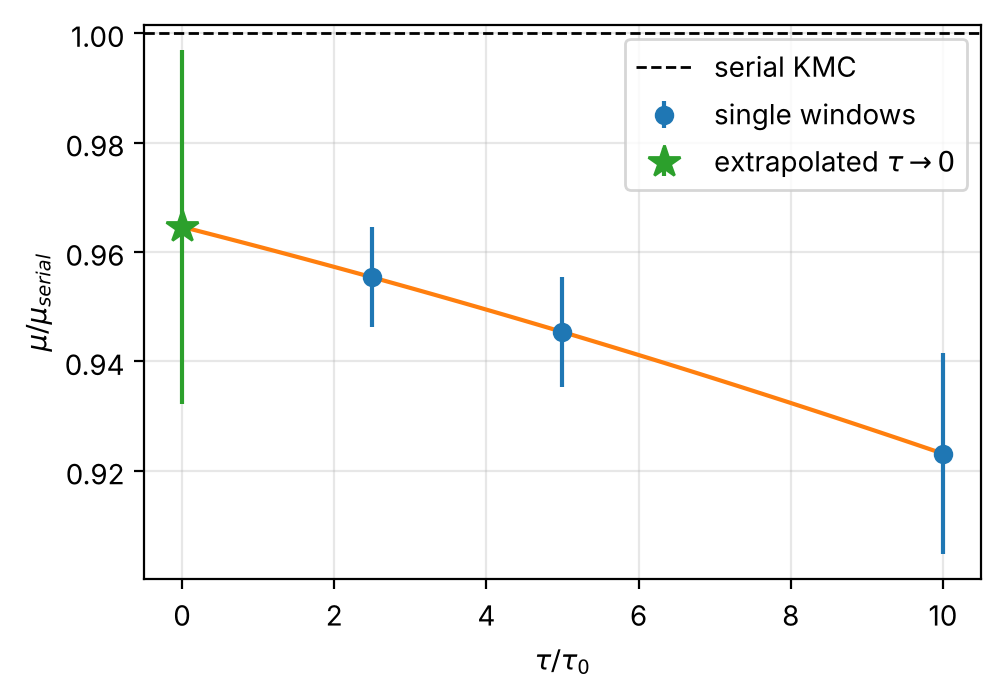

In [3]:
from orchid.lattice import Lattice
from orchid.sublattice_kmc import mobility_sublattice_extrapolated
from orchid.kmc import mobility_interacting
from orchid.constants import kB_eV
T = 300.0; s = 2.5 * kB_eV * T
lat = Lattice(16, a=1.6e-9, seed=3).set_disorder(s)
ref = np.mean([mobility_interacting(lat, T, 0.05 * s, 0.03, n_eq=100000, n_meas=600000, seed=k) for k in (1, 2, 3)])
mu0, info = mobility_sublattice_extrapolated(lat, T, 0.05 * s, 0.03, factors=(10, 5, 2.5),
                                             sim_time_factor=120000, seeds=(1, 2, 3))
x = info["taus"] / info["tau0"]
plt.errorbar(x, info["mu"] / ref, yerr=info["mu_err"] / ref, fmt="o", label="single windows")
xx = np.linspace(0, x.max(), 50); plt.plot(xx, np.polyval(info["coef"][::-1], xx) / ref, "-")
plt.errorbar([0], [mu0 / ref], yerr=[info["err"] / ref], fmt="*", ms=12, label=r"extrapolated $\tau\to0$")
plt.axhline(1, c="k", ls="--", lw=1, label="serial KMC")
plt.xlabel(r"$\tau/\tau_0$"); plt.ylabel(r"$\mu/\mu_{serial}$"); plt.legend();

In [4]:
from orchid import gpu
print("CUDA GPU available:", gpu.available())
# with a GPU: gpu.mobility_independent_gpu(lat, T, 0.05*s, n_carriers=65536)

CUDA GPU available: {'cuda': False, 'cupy': False, 'simulator': False}


**Exercise.** With $s=5\%$ serial work, what is the maximum speed-up on 1000 cores?

<details><summary>Solution</summary>

$1/(0.05+0.95/1000)=19.6$. This is why ORCHID parallelises the outer ensemble loops as well.
</details>

## Quiz

Five questions on this section. Run the cell to see them, then grade yourself with
`quiz("12", answers="abcda")` (one letter per question). The same quiz runs in a terminal
with `orchid quiz 12`.

In [5]:
from orchid.tutorials import quiz
quiz("12")

Quiz 12: Massive parallelism: MPI, threads, GPU and sublattice KMC

Q1. Why is independent-carrier KMC ideal for GPUs?
    (a) Because of Coulomb interactions
    (b) It needs double precision
    (c) It uses the Fenwick tree
    (d) Walkers do not interact, so each GPU thread can propagate one walker

Q2. In the synchronous-sublattice algorithm, blocks of the same sublattice can be updated in parallel because
    (a) They are random
    (b) They are separated by at least the interaction range, so their events are independent within a window
    (c) They use different seeds
    (d) They contain no carriers

Q3. How does v0.4 remove the time-window bias of sublattice KMC?
    (a) By running several windows tau and extrapolating mu(tau) to tau -> 0
    (b) By using one block
    (c) By using the GPU
    (d) By increasing the lattice size

Q4. ORCHID's MPI task farm reproduces the serial result bit-for-bit because
    (a) Results are averaged
    (b) Random seeds are attached to tasks, no

In [6]:
# replace with your answers, e.g. "abcda"
# quiz("12", answers=".....")

<details><summary>Answer key</summary>

`dbaba`. Run `quiz("12", answers="dbaba")` to see the explanation for every question.
</details>

---
[Tutorial index](README.md) · ORCHID documentation · `orchid tutorials`